# Why semigradient TD can diverge

A seven-state Baird-style example isolates the deadly combination of approximation, bootstrapping and off-policy learning. This is an expected-operator illustration, not a sampled-data contest. Feature covariance is singular; reported errors depend on represented values, not arbitrary weight directions.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/decision_lab').is_dir()
sys.path.insert(0, str(ROOT / 'src'))
def read(path): return json.loads((ROOT / path).read_text())


## Inspect the unstable operator

In [2]:
from decision_lab.lecture_studies import baird_operators
phi,c,a=baird_operators()
eigen=np.linalg.eigvals(a)
assert np.linalg.matrix_rank(c)==7 and eigen.real.min()<0
print("operator eigenvalues",eigen)
print("covariance rank",np.linalg.matrix_rank(c))

operator eigenvalues [-4.78500928e-02 -4.43562145e-03  3.29590270e-17  1.14285714e-01
  1.14285714e-01  1.14285714e-01  1.14285714e-01  1.14285714e-01]
covariance rank 7


## Unclipped recorded trajectories

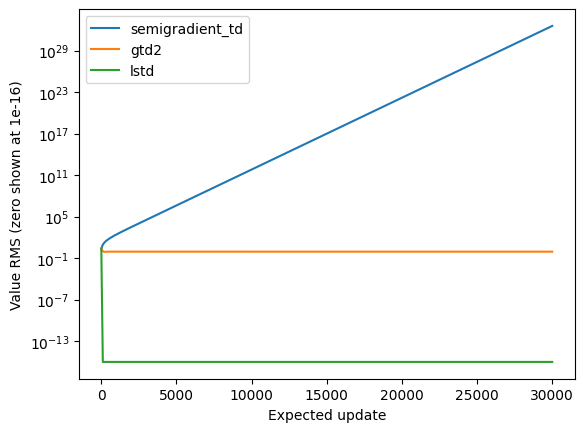

In [3]:
data=np.load(ROOT / "assets/source_data/lectures/baird.npz")
for name in data.files:
    curve=data[name]
    assert np.isfinite(curve).all()
    plt.semilogy(curve[:,0],np.maximum(curve[:,1],1e-16),label=name)
plt.xlabel("Expected update");plt.ylabel("Value RMS (zero shown at 1e-16)");plt.legend();plt.show()

## Distinguish GTD2 from the known-model reference

In [4]:
print(read("results/reference/lectures/metrics.json")["baird"]["protocol"])
print("TD growth",data["semigradient_td"][-1,1]/data["semigradient_td"][0,1])
assert data["gtd2"][-1,1]<data["gtd2"][0,1]

Expected-update Baird-style seven-state counterexample. Behavior stationary state distribution uniform; target always transitions to lower state; gamma .99, zero rewards. Known-model expected operators remove sampling noise. LSTD solves the zero-reward reference; no claim of sampled-data superiority. Singular feature covariance uses a pseudoinverse in MSPBE. No clipping of diverging TD.
TD growth 1.5266420812872098e+32


Full fits: `decision-lab lectures --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.